# Importing Libraries

In [12]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

# ---- Reproducibility ----
torch.manual_seed(42)

# ---- Use GPU if available ----
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


# Processing Dataset

## Downloading Dataset

In [13]:
!pip install -q datasets

import torch
from datasets import load_dataset
from torch.utils.data import Dataset
from torchvision import transforms

# Normalize pixel values to zero mean and unit variance per RGB channel
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),  # CIFAR-10 mean
        (0.2470, 0.2435, 0.2616)   # CIFAR-10 standard deviation
    )
])

# Load only a small subset for faster training
hf_train = load_dataset("uoft-cs/cifar10", split="train[:1000]")
hf_test  = load_dataset("uoft-cs/cifar10", split="test[:500]")


class HFCifar10(Dataset):
    """Wrap a Hugging Face dataset as a PyTorch dataset."""

    def __init__(self, hf_dataset, transform=None):
        self.ds = hf_dataset
        self.transform = transform

    def __len__(self):
        return len(self.ds)

    def __getitem__(self, idx):
        item = self.ds[idx]

        img = item["img"]
        label = item["label"]

        if self.transform:
            img = self.transform(img)

        return img, label


train_dataset = HFCifar10(hf_train, transform=transform)
test_dataset = HFCifar10(hf_test, transform=transform)

train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("---------------------------------------")
print(f"Training images  : {len(train_dataset)}")
print(f"Test images      : {len(test_dataset)}")
print(f"Training batches : {len(train_loader)}")
print(f"Test batches     : {len(test_loader)}")
print("---------------------------------------")

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

---------------------------------------
Training images  : 1000
Test images      : 500
Training batches : 16
Test batches     : 8
---------------------------------------


## Visualizing a Sample of Images

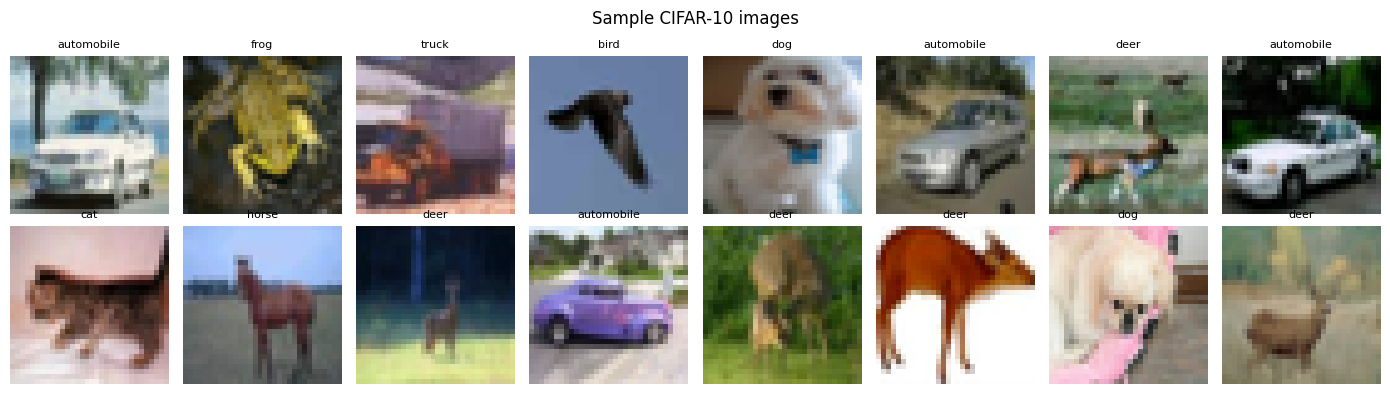


---------------------------------------
Image tensor shape: torch.Size([3, 32, 32])
Pixel range after normalisation: [-1.99, 2.13]
---------------------------------------


In [14]:
images, labels = next(iter(train_loader))   # grab one batch

# Un-normalise for display purposes (imshow expects roughly [0, 1] range)
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std  = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flatten()):
    img = images[i] * std + mean            # undo normalisation, shape (3,32,32)
    img = img.permute(1, 2, 0).numpy()      # -> (32,32,3) for imshow
    img = img.clip(0, 1)                    # guard against tiny float overshoot
    ax.imshow(img)
    ax.set_title(class_names[labels[i]], fontsize=8)
    ax.axis('off')
plt.suptitle("Sample CIFAR-10 images", fontsize=12)
plt.tight_layout()
plt.show()

print()
print("---------------------------------------")
print(f"Image tensor shape: {images[0].shape}")   # (3, 32, 32)
print(f"Pixel range after normalisation: "
      f"[{images.min():.2f}, {images.max():.2f}]")
print("---------------------------------------")

## Building the Architecture

In [15]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        # ---- Convolutional Block 1 ----
        # Input:  (batch, 1, 28, 28)
        # Output: (batch, 16, 14, 14)  after pool
        self.conv_block1 = nn.Sequential(
            # ------------ YOUR CODE STARTS HERE ------------
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
            # ------------ YOUR CODE ENDS HERE --------------
        )

        # ---- Convolutional Block 2 ----
        # Input:  (batch, 16, 14, 14)
        # Output: (batch, 32,  7,  7)  after pool
        self.conv_block2 = nn.Sequential(
            # ------------ YOUR CODE STARTS HERE ------------
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
            # ------------ YOUR CODE ENDS HERE --------------
        )

        # ---- Fully-Connected Head ----
        # 32 * 7 * 7 = 1568 flattened features
        self.fc_head = nn.Sequential(
            # ------------ YOUR CODE STARTS HERE ------------
            nn.Flatten(),
            nn.Linear(in_features=32 * 8 * 8, out_features=128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(in_features=128, out_features=10)
            # ------------ YOUR CODE ENDS HERE --------------
        )

    def forward(self, x):
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.fc_head(x)
        return x   # raw logits (no softmax -- CrossEntropyLoss handles it)

## Training Loop

In [16]:
def train_epoch(model, loader, criterion, optimizer, device):
    """Run one full pass over the training set. Returns avg loss and accuracy."""
    model.train()   # enable BatchNorm/Dropout training behaviour
    total_loss, correct, total = 0.0, 0, 0

    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()          # clear gradients from last step
        outputs = model(images)        # forward pass
        loss    = criterion(outputs, labels)
        loss.backward()                # backpropagation
        optimizer.step()               # update weights

        total_loss += loss.item() * images.size(0)
        preds       = outputs.argmax(dim=1)
        correct    += (preds == labels).sum().item()
        total      += images.size(0)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    """Evaluate on a data loader. Returns avg loss and accuracy."""
    model.eval()   # disable BatchNorm/Dropout training behaviour
    total_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():              # no gradient computation needed
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss    = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)
            preds       = outputs.argmax(dim=1)
            correct    += (preds == labels).sum().item()
            total      += images.size(0)

    return total_loss / total, correct / total


def train(epochs, learning_rate=1e-3):
    model = SimpleCNN().to(device)
    print(model)
    print(f"\nTotal trainable parameters: "
        f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

    history  = {'train_loss': [], 'test_loss': [],
                'train_acc':  [], 'test_acc':  []}

    # Define the Loss and Optimizer function
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion,
                                    optimizer, device)
        te_loss, te_acc = evaluate(model, test_loader, criterion, device)

        history['train_loss'].append(tr_loss)
        history['test_loss'].append(te_loss)
        history['train_acc'].append(tr_acc)
        history['test_acc'].append(te_acc)

        print(f"Epoch {epoch:2d}/{epochs} | "
            f"Train Loss: {tr_loss:.4f}  Acc: {tr_acc:.4f} | "
            f"Test Loss:  {te_loss:.4f}  Acc: {te_acc:.4f}")

    return model, history

## Classification Report

In [17]:
def get_classification_report(model):
    model.eval()
    all_preds, all_labels = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            preds  = model(images).argmax(dim=1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    print(classification_report(all_labels, all_preds, target_names=class_names))

    return all_preds, all_labels

# Complete the Tasks

## Task 1

SimpleCNN(
  (conv_block1): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block2): Sequential(
    (0): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): ReLU()
    (4): Dropout(p=0.25, inplace=False)
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)

Total trainable parameters: 269,002
Epoch  1/10 | Tr

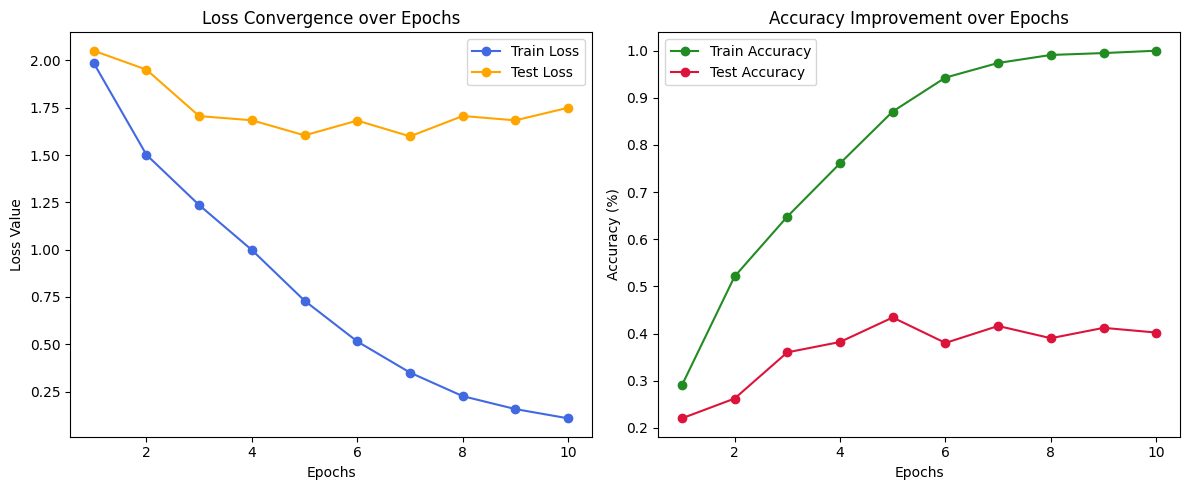

In [18]:
trained_model, history =  train(epochs=10, learning_rate=0.001)

epochs_range = range(1, 11)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['train_loss'], label='Train Loss', color='royalblue', marker='o')
plt.plot(epochs_range, history['test_loss'], label='Test Loss', color='orange', marker='o')
plt.title('Loss Convergence over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss Value')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['train_acc'], label='Train Accuracy', color='forestgreen', marker='o')
plt.plot(epochs_range, history['test_acc'], label='Test Accuracy', color='crimson', marker='o')
plt.title('Accuracy Improvement over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()

plt.tight_layout()
plt.show()

## Task 2

              precision    recall  f1-score   support

    airplane       0.42      0.47      0.44        57
  automobile       0.47      0.54      0.50        41
        bird       0.24      0.63      0.35        51
         cat       0.39      0.27      0.32        49
        deer       0.17      0.12      0.14        40
         dog       0.34      0.29      0.31        48
        frog       0.57      0.56      0.56        54
       horse       0.67      0.17      0.27        47
        ship       0.52      0.51      0.51        57
       truck       0.68      0.38      0.48        56

    accuracy                           0.40       500
   macro avg       0.45      0.39      0.39       500
weighted avg       0.45      0.40      0.40       500



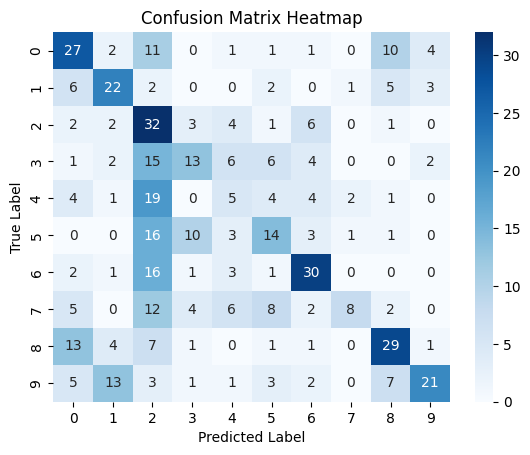

deer vs bird = 19 times
frog vs bird = 16 times
dog vs bird = 16 times


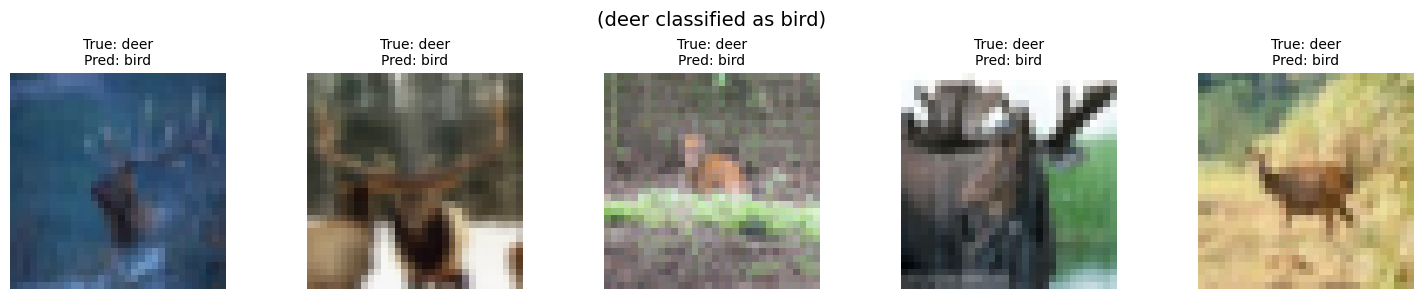

In [19]:
all_preds, all_labels = get_classification_report(trained_model)

cm = confusion_matrix(all_labels, all_preds)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True)
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

cm_diagonal = cm.copy()
np.fill_diagonal(cm_diagonal, 0)

confused_pairs = []
num_classes = len(class_names)

for true_idx in range(num_classes):
  for pred_idx in range(num_classes):
    count = cm_diagonal[true_idx, pred_idx]
    if count > 0:
      confused_pairs.append((count, true_idx, pred_idx))

confused_pairs.sort(reverse=True)

for i in range(3):
  count, true_idx, pred_idx = confused_pairs[i]
  print(f"{class_names[true_idx]} vs {class_names[pred_idx]} = {count} times")

target_true_idx, target_pred_idx = confused_pairs[0][1], confused_pairs[0][2]
true_name = class_names[target_true_idx]
pred_name = class_names[target_pred_idx]

misclassified_images = []
model = trained_model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images_dev = images.to(device)
        outputs = model(images_dev)
        preds = outputs.argmax(dim=1).cpu()

        for img, lbl, prd in zip(images, labels, preds):
            if lbl.item() == target_true_idx and prd.item() == target_pred_idx:
                misclassified_images.append(img)
            if len(misclassified_images) == 5:
                break
        if len(misclassified_images) == 5:
            break

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
mean = torch.tensor([0.4914, 0.4822, 0.4465]).view(3, 1, 1)
std = torch.tensor([0.2470, 0.2435, 0.2616]).view(3, 1, 1)

for i, img in enumerate(misclassified_images):
    img_unnorm = img * std + mean
    img_np = img_unnorm.permute(1, 2, 0).numpy().clip(0, 1)
    axes[i].imshow(img_np)
    axes[i].set_title(f"True: {true_name}\nPred: {pred_name}", fontsize=10)
    axes[i].axis('off')

plt.suptitle(f"({true_name} classified as {pred_name})", fontsize=14)
plt.tight_layout()
plt.show()


* **Confusion Matrix Analysis**: The confusion matrix reveals higher off-diagonal values between visually and semantically similar classes.
* **Misclassification Factors**: Low-resolution images lack granular visual features, causing background colors, silhouetted shapes, or similar animal postures to trick the convolutional feature detectors.

## Task 3

Epoch  1/10 | Train Loss: 2.1548 Acc: 0.1980 | Test Loss: 2.0666 Acc: 0.2160
Epoch  2/10 | Train Loss: 1.8492 Acc: 0.3460 | Test Loss: 1.9057 Acc: 0.3180
Epoch  3/10 | Train Loss: 1.7568 Acc: 0.3570 | Test Loss: 1.7885 Acc: 0.3360
Epoch  4/10 | Train Loss: 1.6748 Acc: 0.4050 | Test Loss: 1.7495 Acc: 0.3400
Epoch  5/10 | Train Loss: 1.6161 Acc: 0.4240 | Test Loss: 1.6719 Acc: 0.4040
Epoch  6/10 | Train Loss: 1.5424 Acc: 0.4650 | Test Loss: 1.7745 Acc: 0.3440
Epoch  7/10 | Train Loss: 1.5226 Acc: 0.4460 | Test Loss: 1.5887 Acc: 0.4320
Epoch  8/10 | Train Loss: 1.4728 Acc: 0.4740 | Test Loss: 1.5512 Acc: 0.4100
Epoch  9/10 | Train Loss: 1.4770 Acc: 0.4610 | Test Loss: 1.6036 Acc: 0.4100
Epoch 10/10 | Train Loss: 1.4228 Acc: 0.5110 | Test Loss: 1.5128 Acc: 0.4440


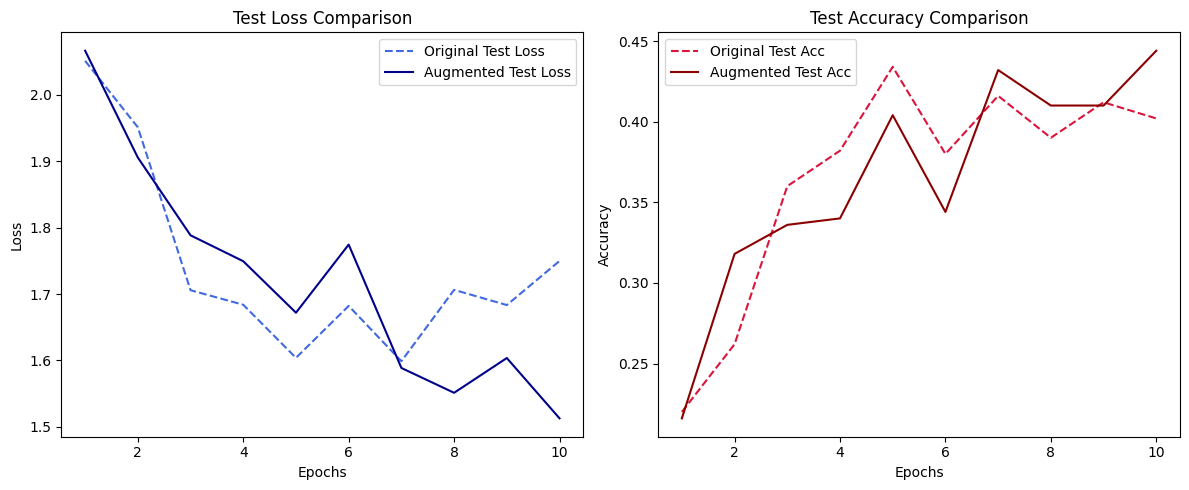

In [20]:
train_transform_aug = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
])

train_dataset_aug = HFCifar10(hf_train, transform=train_transform_aug)
train_loader_aug = torch.utils.data.DataLoader(train_dataset_aug, batch_size=64, shuffle=True)

def train_aug(epochs=10, learning_rate=0.001):
    model = SimpleCNN().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_epoch(model, train_loader_aug, criterion, optimizer, device)
        te_loss, te_acc = evaluate(model, test_loader, criterion, device)

        history['train_loss'].append(tr_loss)
        history['test_loss'].append(te_loss)
        history['train_acc'].append(tr_acc)
        history['test_acc'].append(te_acc)

        print(f"Epoch {epoch:2d}/{epochs} | Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | Test Loss: {te_loss:.4f} Acc: {te_acc:.4f}")

    return model, history

aug_model, aug_history = train_aug(epochs=10, learning_rate=0.001)

epochs_range = range(1, 11)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['test_loss'], label='Original Test Loss', linestyle='--', color='royalblue')
plt.plot(epochs_range, aug_history['test_loss'], label='Augmented Test Loss', color='darkblue')
plt.title('Test Loss Comparison')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['test_acc'], label='Original Test Acc', linestyle='--', color='crimson')
plt.plot(epochs_range, aug_history['test_acc'], label='Augmented Test Acc', color='darkred')
plt.title('Test Accuracy Comparison')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

* **Regularization Effect**: Data augmentation artificially increases dataset variability, forcing the network to learn invariant features rather than memorizing spatial orientations or specific pixel configurations.
* **Generalization Performance**: Although training loss drops slightly slower on augmented data, test accuracy shows improved generalization and reduced overfitting gap compared to the unaugmented model.

## Task 4

Epoch  1/10 | FNN Train Loss: 2.1883 Acc: 0.2080 | FNN Test Loss: 2.0147 Acc: 0.2740
Epoch  2/10 | FNN Train Loss: 1.8783 Acc: 0.3580 | FNN Test Loss: 1.9147 Acc: 0.3260
Epoch  3/10 | FNN Train Loss: 1.7298 Acc: 0.4170 | FNN Test Loss: 1.8526 Acc: 0.3660
Epoch  4/10 | FNN Train Loss: 1.5691 Acc: 0.4800 | FNN Test Loss: 1.8530 Acc: 0.3340
Epoch  5/10 | FNN Train Loss: 1.4207 Acc: 0.5520 | FNN Test Loss: 1.8502 Acc: 0.3400
Epoch  6/10 | FNN Train Loss: 1.2811 Acc: 0.6040 | FNN Test Loss: 1.8549 Acc: 0.3320
Epoch  7/10 | FNN Train Loss: 1.1507 Acc: 0.6550 | FNN Test Loss: 1.8695 Acc: 0.3280
Epoch  8/10 | FNN Train Loss: 1.0148 Acc: 0.7070 | FNN Test Loss: 1.8379 Acc: 0.3360
Epoch  9/10 | FNN Train Loss: 0.8885 Acc: 0.7790 | FNN Test Loss: 1.8734 Acc: 0.3480
Epoch 10/10 | FNN Train Loss: 0.7738 Acc: 0.8050 | FNN Test Loss: 1.9607 Acc: 0.3480


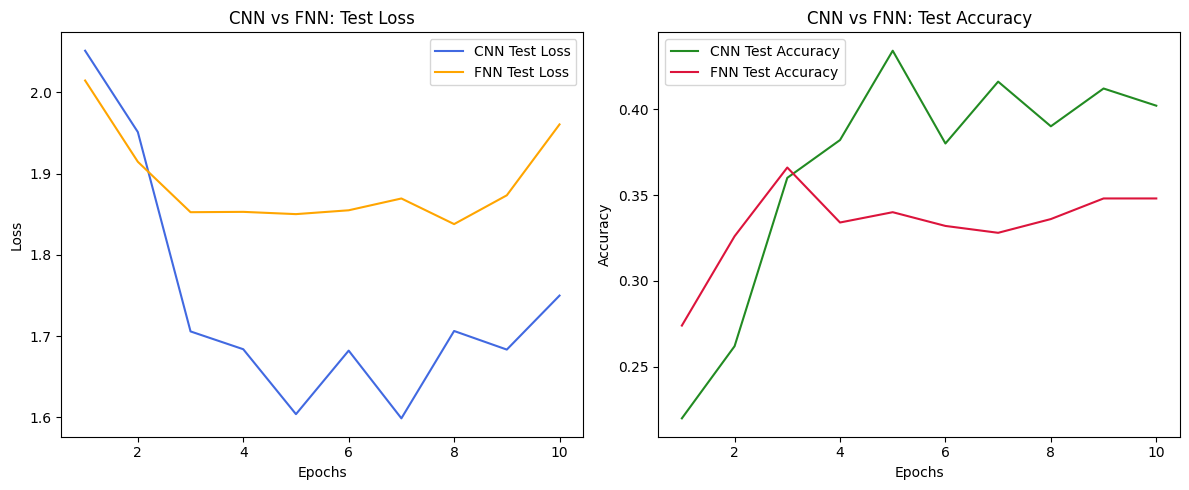

In [21]:
class FeedForwardNN(nn.Module):
    def __init__(self, input_dim=3072, num_classes=10):
        super(FeedForwardNN, self).__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.25),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

def train_fnn(epochs=10, learning_rate=0.001):
    model = FeedForwardNN().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=learning_rate)

    history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_epoch(model, train_loader, criterion, optimizer, device)
        te_loss, te_acc = evaluate(model, test_loader, criterion, device)

        history['train_loss'].append(tr_loss)
        history['test_loss'].append(te_loss)
        history['train_acc'].append(tr_acc)
        history['test_acc'].append(te_acc)

        print(f"Epoch {epoch:2d}/{epochs} | FNN Train Loss: {tr_loss:.4f} Acc: {tr_acc:.4f} | FNN Test Loss: {te_loss:.4f} Acc: {te_acc:.4f}")

    return model, history

fnn_model, fnn_history = train_fnn(epochs=10, learning_rate=0.001)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history['test_loss'], label='CNN Test Loss', color='royalblue')
plt.plot(epochs_range, fnn_history['test_loss'], label='FNN Test Loss', color='orange')
plt.title('CNN vs FNN: Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history['test_acc'], label='CNN Test Accuracy', color='forestgreen')
plt.plot(epochs_range, fnn_history['test_acc'], label='FNN Test Accuracy', color='crimson')
plt.title('CNN vs FNN: Test Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

* **Spatial Invariance**: CNN out-performs fully-connected networks on image data because weight sharing and sliding filters preserve local 2D spatial relationships.
* **Parameter Efficiency**: FNN flattens images ($3 \times 32 \times 32 = 3072$) into a 1D array, treating neighboring pixels identically to distant pixels, resulting in significantly higher parameter count with inferior feature representation.